===== 基准仿真结果 =====
seed                  42.00
rho                    0.30
p                      3.00
q                      3.00
E                      1.00
B                      1.00
c                      0.00
surv                   5.00
collapse_event         1.00
W_T                  -64.00
HH_trades            294.00
HC_trades            235.00
CC_trades            620.00
final_wealth         986.00
mean_final_wealth      9.86
active_H_final         0.00
active_C_final         2.00
converted_H           70.00
expelled_count        55.00
death_count            0.00
dtype: float64

===== 制度比较 =====
   surv      W_T  HH_trades  HC_trades  CC_trades  final_wealth
E                                                              
0  4.00 -1126.22     187.54     255.18     938.19          4.04
1  5.37    20.72     280.78     241.58     551.20       1051.78

===== 驱逐制度处理效应 =====
                  ATE     SE
surv             1.37  0.051
W_T           1146.94  9.359
HH_trades       93.24  

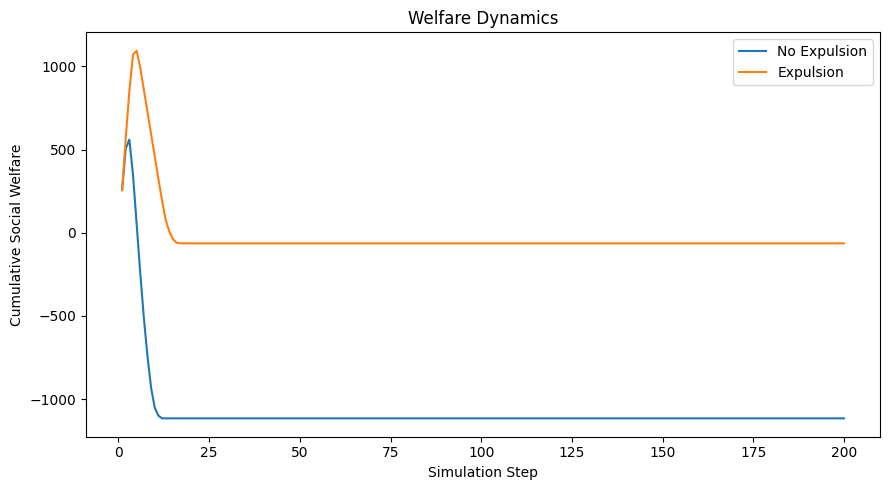


Welfare accounting check passed.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy import stats

@dataclass
class Config:
    N: int = 100
    a: int = 3
    p: int = 3
    q: int = 3
    w0: float = 10.0
    T: int = 200
    rho: float = 0.30
    c: float = 0.0

    bankruptcy: bool = True
    expulsion: bool = True

    gHH: float = 2.0
    gHC_H: float = -2.0
    gHC_C: float = 2.0
    gCC: float = -1.0


def simulate(cfg, seed=1):
    rng = np.random.default_rng(seed)
    N = cfg.N

    # True = 老实人 H；False = 骗子 C
    honest = np.ones(N, dtype=bool)
    nC = round(N * cfg.rho)
    honest[rng.choice(N, nC, replace=False)] = False

    H0 = int(honest.sum())

    wealth = np.full(N, cfg.w0, dtype=float)
    m = np.zeros(N, dtype=int)
    reports = np.zeros(N, dtype=int)

    # 退出市场与死亡分开记录
    active = np.ones(N, dtype=bool)
    dead = np.zeros(N, dtype=bool)
    expelled = np.zeros(N, dtype=bool)

    # 每个人的黑名单
    blacklist = [set() for _ in range(N)]

    # 可交易目录：起初包含除自己外所有人
    directory = [
        set(range(N)) - {i}
        for i in range(N)
    ]

    total_HH = total_HC = total_CC = 0
    total_welfare = 0.0

    collapse_time = cfg.T
    collapse_event = 0

    history = []

    # 初始状态检查
    if H0 <= 0:
        raise ValueError("初始老实人数必须大于 0")

    for t in range(1, cfg.T + 1):

        # ----------------------------
        # 1. 步初快照
        # ----------------------------
        start_honest = honest.copy()
        start_active = active.copy()

        degree = np.zeros(N, dtype=int)
        delta_w = np.zeros(N)
        delta_m = np.zeros(N, dtype=int)
        delta_r = np.zeros(N, dtype=int)

        step_HH = step_HC = step_CC = 0
        step_welfare = 0.0

        # ----------------------------
        # 2. 随机配对
        # ----------------------------
        candidates = []

        for i in range(N):
            if not start_active[i]:
                continue

            for j in directory[i]:
                if j <= i or not start_active[j]:
                    continue

                if j in blacklist[i] or i in blacklist[j]:
                    continue

                candidates.append((i, j))

        rng.shuffle(candidates)

        # 每人每步最多 a 次交易
        # 每个无序配对最多一次
        matched = []

        for i, j in candidates:
            if degree[i] >= cfg.a:
                continue
            if degree[j] >= cfg.a:
                continue

            matched.append((i, j))
            degree[i] += 1
            degree[j] += 1

        # ----------------------------
        # 3. 同步计算交易收益
        # ----------------------------
        for i, j in matched:

            hi = start_honest[i]
            hj = start_honest[j]

            if hi and hj:
                delta_w[i] += cfg.gHH
                delta_w[j] += cfg.gHH

                step_HH += 1
                step_welfare += 2 * cfg.gHH

            elif hi != hj:
                H = i if hi else j
                C = j if hi else i

                delta_w[H] += cfg.gHC_H
                delta_w[C] += cfg.gHC_C

                delta_m[H] += 1
                delta_r[C] += 1

                # 老实人拉黑骗子
                blacklist[H].add(C)

                # 骗子从老实人的交易目录中删除
                directory[H].discard(C)

                step_HC += 1
                step_welfare += (
                    cfg.gHC_H + cfg.gHC_C
                )

            else:
                delta_w[i] += cfg.gCC
                delta_w[j] += cfg.gCC

                # 骗子互相拉黑，但不举报
                blacklist[i].add(j)
                blacklist[j].add(i)

                directory[i].discard(j)
                directory[j].discard(i)

                step_CC += 1
                step_welfare += 2 * cfg.gCC

        # ----------------------------
        # 4. 统一结算
        # ----------------------------
        wealth += delta_w
        m += delta_m
        reports += delta_r

        # ----------------------------
        # 5. 老实人转化为骗子
        # ----------------------------
        converted = (
            start_honest &
            (m >= cfg.p)
        )
        honest[converted] = False

        # ----------------------------
        # 6. 生存消耗
        # ----------------------------
        # c=0：基准模型
        # c>0：所有未死亡者均消耗，包括退出者
        if cfg.c > 0:
            wealth[~dead] -= cfg.c

        # ----------------------------
        # 7. 破产与死亡
        # ----------------------------
        if cfg.c > 0:
            # 扩展模型：资金耗尽定义为死亡
            newly_dead = (wealth <= 0) & (~dead)
            dead[newly_dead] = True
            active[newly_dead] = False

        elif cfg.bankruptcy:
            # 基准模型：资金耗尽退出市场
            bankrupt = (wealth <= 0) & active
            active[bankrupt] = False
            wealth[bankrupt] = 0.0

        # ----------------------------
        # 8. 举报驱逐
        # ----------------------------
        if cfg.expulsion:
            newly_expelled = (
                (reports >= cfg.q) &
                active
            )

            expelled[newly_expelled] = True
            active[newly_expelled] = False

        # 退出者从所有人的目录中移除
        inactive_ids = np.flatnonzero(~active)

        for i in range(N):
            directory[i].difference_update(inactive_ids)

        # ----------------------------
        # 9. 统计市场状态
        # ----------------------------
        active_H = int(np.sum(active & honest))
        active_C = int(np.sum(active & ~honest))

        total_HH += step_HH
        total_HC += step_HC
        total_CC += step_CC
        total_welfare += step_welfare

        # 崩溃首次发生时间
        if (
            collapse_event == 0
            and active_H <= 0.1 * H0
        ):
            collapse_time = t
            collapse_event = 1

        history.append({
            "step": t,
            "active_H": active_H,
            "active_C": active_C,
            "HH": step_HH,
            "HC": step_HC,
            "CC": step_CC,
            "step_welfare": step_welfare,
            "cumulative_welfare": total_welfare,
            "total_wealth": wealth.sum(),
            "alive": int((~dead).sum()),
            "expelled": int(expelled.sum())
        })

    # ----------------------------
    # 10. 固定观察期结果
    # ----------------------------
    result = {
        "seed": seed,
        "rho": cfg.rho,
        "p": cfg.p,
        "q": cfg.q,
        "E": int(cfg.expulsion),
        "B": int(cfg.bankruptcy),
        "c": cfg.c,

        "surv": collapse_time,
        "collapse_event": collapse_event,

        "W_T": total_welfare,
        "HH_trades": total_HH,
        "HC_trades": total_HC,
        "CC_trades": total_CC,

        "final_wealth": wealth.sum(),
        "mean_final_wealth": wealth.mean(),

        "active_H_final": active_H,
        "active_C_final": active_C,
        "converted_H": int(np.sum(~honest)) - nC,
        "expelled_count": int(expelled.sum()),
        "death_count": int(dead.sum())
    }

    return result, pd.DataFrame(history)


# ====================================
# A. 单次基准仿真
# ====================================

cfg = Config()

result, history = simulate(cfg, seed=42)

print("===== 基准仿真结果 =====")
print(pd.Series(result))

history.to_csv(
    "baseline_history.csv",
    index=False
)


# ====================================
# B. 福利分析：驱逐制度对照实验
# ====================================

results = []

for seed in range(1, 101):

    for E in [False, True]:

        cfg = Config(expulsion=E)

        res, _ = simulate(cfg, seed=seed)
        results.append(res)

df = pd.DataFrame(results)

df.to_csv(
    "welfare_results.csv",
    index=False
)

outcomes = [
    "surv",
    "W_T",
    "HH_trades",
    "HC_trades",
    "CC_trades",
    "final_wealth"
]

summary = df.groupby("E")[outcomes].mean()

print("\n===== 制度比较 =====")
print(summary.round(2))


# ====================================
# C. 配对处理效应
# ====================================

wide = df.pivot(
    index="seed",
    columns="E",
    values=outcomes
)

effects = {}

for y in outcomes:
    diff = wide[(y, 1)] - wide[(y, 0)]

    effects[y] = {
        "ATE": diff.mean(),
        "SE": diff.std(ddof=1) / np.sqrt(len(diff))
    }

outcomes = [
    "surv",
    "W_T",
    "HH_trades",
    "HC_trades",
    "CC_trades",
    "final_wealth"
]

# 每个随机种子对应有驱逐和无驱逐两组结果
wide = df.pivot(
    index="seed",
    columns="E",
    values=outcomes
)

results = []

for y in outcomes:

    # 同一个 seed 下的配对差值
    diff = (
        wide[(y, 1)] - wide[(y, 0)]
    ).dropna()

    n = len(diff)

    # 平均处理效应
    ate = diff.mean()

    # 配对差值标准差
    sd = diff.std(ddof=1)

    # 标准误
    se = sd / np.sqrt(n)

    # t 统计量与双侧 p 值
    dfree = n - 1

    if se > 0:
        t_stat = ate / se
        p_value = 2 * stats.t.sf(
            abs(t_stat), df=dfree
        )
    else:
        t_stat = np.nan
        p_value = np.nan

    # 95% 置信区间
    t_critical = stats.t.ppf(
        0.975, df=dfree
    )

    ci_low = ate - t_critical * se
    ci_high = ate + t_critical * se

    # 显著性星号
    if p_value < 0.01:
        stars = "***"
    elif p_value < 0.05:
        stars = "**"
    elif p_value < 0.10:
        stars = "*"
    else:
        stars = ""

    results.append({
        "Variable": y,
        "N": n,
        "ATE": ate,
        "SE": se,
        "t-stat": t_stat,
        "p-value": p_value,
        "95% CI Lower": ci_low,
        "95% CI Upper": ci_high,
        "Stars": stars
    })

# 保存完整数值结果
results_df = pd.DataFrame(results)

results_df.to_csv(
    "paired_ATE_full_results.csv",
    index=False
)

# 生成论文展示表格
paper_table = results_df.copy()

paper_table["ATE"] = (
    paper_table["ATE"].map(lambda x: f"{x:.3f}")
    + paper_table["Stars"]
)

paper_table["SE"] = paper_table["SE"].map(
    lambda x: f"({x:.3f})"
)

paper_table["p-value"] = paper_table["p-value"].map(
    lambda x: "<0.001" if x < 0.001
    else f"{x:.4f}"
)

paper_table["95% CI"] = [
    f"[{lo:.2f}, {hi:.2f}]"
    for lo, hi in zip(
        results_df["95% CI Lower"],
        results_df["95% CI Upper"]
    )
]

paper_table = paper_table[
    ["Variable", "N", "ATE", "SE",
     "t-stat", "p-value", "95% CI"]
]

print("\n===== Paired ATE Results =====")
print(paper_table.to_string(index=False))

paper_table.to_csv(
    "paired_ATE_paper_table.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nSignificance levels:")
print("* p<0.10, ** p<0.05, *** p<0.01")应 =====")
print(effects_df.round(3))


# ====================================
# D. 绘制福利随时间变化
# ====================================

cfg_no = Config(expulsion=False)
cfg_yes = Config(expulsion=True)

_, hist_no = simulate(cfg_no, seed=42)
_, hist_yes = simulate(cfg_yes, seed=42)

plt.figure(figsize=(9, 5))

plt.plot(
    hist_no["step"],
    hist_no["cumulative_welfare"],
    label="No Expulsion"
)

plt.plot(
    hist_yes["step"],
    hist_yes["cumulative_welfare"],
    label="Expulsion"
)

plt.xlabel("Simulation Step")
plt.ylabel("Cumulative Social Welfare")
plt.title("Welfare Dynamics")
plt.legend()
plt.tight_layout()
plt.savefig("welfare_dynamics.png", dpi=200)
plt.show()


# ====================================
# E. 福利指标一致性检验
# ====================================

assert np.isclose(
    result["W_T"],
    4 * result["HH_trades"]
    - 2 * result["CC_trades"]
)

print("\nWelfare accounting check passed.")